# Q-Learning on Taxi-v3

A tabular **Q-Learning** agent that learns to drive a taxi in Gymnasium's [Taxi-v3](https://gymnasium.farama.org/environments/toy_text/taxi/): pick up the passenger and drop them off at their destination in as few steps as possible.

Built for Unit 2 of the [Hugging Face Deep Reinforcement Learning Course](https://huggingface.co/learn/deep-rl-course/en/unit2/hands-on).

**Result:** mean reward **8.07 +/- 2.68** over 100 fixed evaluation episodes. The trained agent, its model card and a replay video are on the Hugging Face Hub: [Ebishj/q-Taxi-v3](https://huggingface.co/Ebishj/q-Taxi-v3).

## 1. Setup

`gymnasium` is pinned to **1.2.3**, the last release before Taxi-v4 was added (in 1.3.0). Recent versions, such as 1.4.0, no longer include Taxi-v3.

In [70]:
!pip install -q gymnasium==1.2.3 pygame imageio imageio_ffmpeg huggingface_hub

In [71]:
import os                                       # to set pygame's three settings below
os.environ["PYGAME_HIDE_SUPPORT_PROMPT"] = "1"  # hide pygame's greeting message
os.environ["SDL_AUDIODRIVER"] = "dummy"         # Colab has no sound card: skip audio warnings
os.environ["SDL_VIDEODRIVER"] = "dummy"         # Colab has no screen: draw off-screen

import pickle                                   # read the published agent's file (q-learning.pkl)
import random                                   # random numbers for ε-greedy and the replay's start

import gymnasium as gym                         # the Taxi-v3 environment
import imageio                                  # save the replay frames as an mp4 video
import numpy as np                              # the Q-table and its maths (argmax, max, mean, std)
from IPython.display import Video               # play the replay video in the notebook
from PIL import Image                           # show a picture of the map
from tqdm.auto import tqdm                      # progress bars for training and evaluation
import matplotlib.pyplot as plt                 # the learning curve plot

## 2. The environment

- A 5×5 grid with four pick-up and drop-off locations: **R**ed, **G**reen, **Y**ellow and **B**lue.
- **500 states:** 25 taxi positions × 5 passenger locations (one of the four, or inside the taxi) × 4 destinations.
- **6 actions:** move south, north, east or west, pick up, drop off.
- **Rewards:** −1 per step, +20 for delivering the passenger, −10 for an illegal pick-up or drop-off.

In [72]:
env = gym.make("Taxi-v3", render_mode="rgb_array")

state_space = env.observation_space.n
action_space = env.action_space.n
print("There are", state_space, "possible states")
print("There are", action_space, "possible actions")

There are 500 possible states
There are 6 possible actions


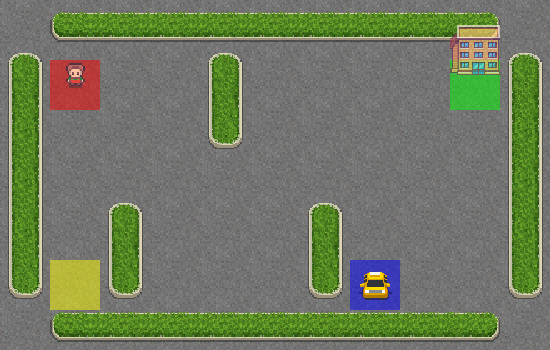

In [73]:
# A starting position: the yellow taxi, the passenger (small figure) and the destination (building)
env.reset()
Image.fromarray(env.render())

## 3. The Q-table

One row per state and one column per action (500 × 6), all starting at zero.

In [74]:
def initialize_q_table(state_space, action_space):
    Qtable = np.zeros((state_space, action_space))
    return Qtable


Qtable_taxi = initialize_q_table(state_space, action_space)
print("Q-table shape:", Qtable_taxi.shape)

Q-table shape: (500, 6)


## 4. Policies

- **ε-greedy** (used while training): with probability ε take a random action (explore), otherwise take the best known action (exploit).
- **Greedy** (used after training): always take the best known action.

In [75]:
def greedy_policy(Qtable, state):
    # Exploitation: the action with the highest Q-value in this state
    action = np.argmax(Qtable[state][:])
    return action


def epsilon_greedy_policy(Qtable, state, epsilon):
    random_num = random.uniform(0, 1)
    if random_num > epsilon:
        action = greedy_policy(Qtable, state)  # exploitation
    else:
        action = env.action_space.sample()     # exploration
    return action

## 5. Hyperparameters

The course's settings. `eval_seed` fixes the 100 starting positions used for evaluation, so every agent in the course is scored on the same episodes. Don't change it.

In [76]:
# Training parameters
n_training_episodes = 25000   # total training episodes
learning_rate = 0.7           # learning rate (alpha)

# Evaluation parameters
n_eval_episodes = 200         # total number of test episodes

# Environment parameters
env_id = "Taxi-v3"            # name of the environment
max_steps = 99                # max steps per episode
gamma = 0.95                  # discount rate

# Exploration parameters
max_epsilon = 1.0             # exploration probability at the start
min_epsilon = 0.05            # minimum exploration probability
decay_rate = 0.005            # exponential decay rate for the exploration probability

## 6. Training

After each step, the agent updates its estimate for the action it took:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \left[ r + \gamma \max_{a'} Q(s',a') - Q(s,a) \right]$$

ε starts at 1.0 (all random) and decays exponentially towards 0.05.

In [77]:
def train(n_training_episodes, min_epsilon, max_epsilon, decay_rate, env, max_steps, Qtable):
      episode_rewards = []  # total reward of each training episode, for the learning curve
      for episode in tqdm(range(n_training_episodes)):
          # Less exploration as training goes on
          epsilon = min_epsilon + (max_epsilon - min_epsilon) * np.exp(-decay_rate * episode)
          state, info = env.reset()
          total_reward = 0

          for step in range(max_steps):
              action = epsilon_greedy_policy(Qtable, state, epsilon)
              new_state, reward, terminated, truncated, info = env.step(action)
              total_reward += reward

              # Q-learning update
              Qtable[state][action] = Qtable[state][action] + learning_rate * (
                  reward + gamma * np.max(Qtable[new_state]) - Qtable[state][action]
              )

              if terminated or truncated:
                  break
              state = new_state
          episode_rewards.append(total_reward)
      return Qtable, episode_rewards

In [78]:
  Qtable_taxi, training_rewards = train(n_training_episodes, min_epsilon, max_epsilon, decay_rate, env, max_steps, Qtable_taxi)

  0%|          | 0/25000 [00:00<?, ?it/s]

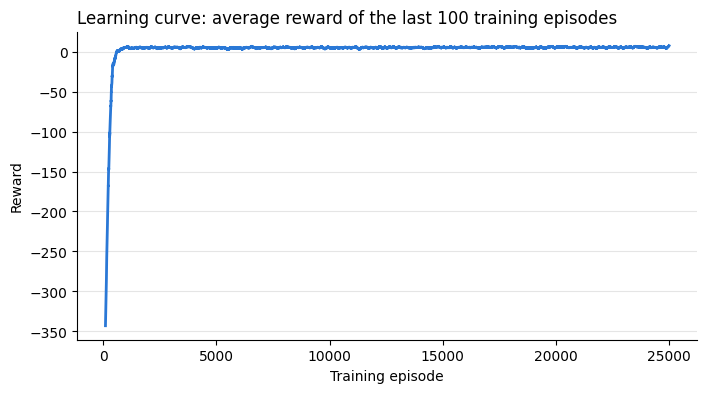

In [79]:
  window = 100  # average over the last 100 episodes to smooth out the noise
  moving_avg = np.convolve(training_rewards, np.ones(window) / window, mode="valid")

  fig, ax = plt.subplots(figsize=(8, 4))
  ax.plot(np.arange(window, len(training_rewards) + 1), moving_avg, color="#2a78d6", linewidth=2)
  ax.set_title("Learning curve: average reward of the last 100 training episodes", loc="left")
  ax.set_xlabel("Training episode")
  ax.set_ylabel("Reward")
  ax.grid(axis="y", color="#e5e5e5")
  ax.spines[["top", "right"]].set_visible(False)
  plt.show()

In [80]:
np.save("qtable_taxi.npy", Qtable_taxi)  # Saving trained agent - reload later with np.load("qtable_taxi.npy")

## 7. Evaluation

The greedy agent plays the 100 seeded episodes. The course's pass mark is **mean − std ≥ 4.5**.

Training is random, so the score varies a little from run to run. Section 10 reproduces the published agent's exact score.

In [81]:
def evaluate_agent(env, max_steps, n_eval_episodes, Q):
       episode_rewards = []
       for episode in tqdm(range(n_eval_episodes)):
           state, info = env.reset()  # random start
           total_rewards_ep = 0

           for step in range(max_steps):
               action = greedy_policy(Q, state)
               new_state, reward, terminated, truncated, info = env.step(action)
               total_rewards_ep += reward
               if terminated or truncated:
                   break
               state = new_state
           episode_rewards.append(total_rewards_ep)

       mean_reward = np.mean(episode_rewards)
       std_reward = np.std(episode_rewards)
       return mean_reward, std_reward

In [82]:
mean_reward, std_reward = evaluate_agent(env, max_steps, n_eval_episodes, Qtable_taxi)
print(f"Mean reward = {mean_reward:.2f} +/- {std_reward:.2f}")

  0%|          | 0/200 [00:00<?, ?it/s]

Mean reward = 7.51 +/- 2.47


## 8. Watch the agent

One episode from a random start, at 1 frame per second.

In [83]:
def record_video(env, Qtable, out_path, fps=1):
    images = []
    state, info = env.reset(seed=random.randint(0, 500))
    images.append(env.render())
    terminated = truncated = False
    while not (terminated or truncated):
        action = greedy_policy(Qtable, state)
        state, reward, terminated, truncated, info = env.step(action)
        images.append(env.render())
    imageio.mimsave(out_path, images, fps=fps, macro_block_size=1)

In [84]:
record_video(env, Qtable_taxi, "replay.mp4")
Video("replay.mp4", embed=True)

## Takeaways

- **It works:** after 25,000 training episodes, the greedy agent delivers the passenger from random starts, with a mean reward of **8.07 +/- 2.68** over 200 test episodes.
- **Learning is fast:** the average reward climbs from about −330 (random driving) to above 0 within roughly 600 episodes, then levels off. Most of the 25,000 episodes only polish the Q-table.
- **Training scores lower than testing:** the curve levels off around 6, below the test score, because 5% of training moves are still random (ε = 0.05).
- **A small table is enough:** Taxi has only 500 states, so the whole agent is a 500 × 6 table.
- **It only knows this map:** the table has one row per state of this exact 5×5 map, so a different or bigger map would need retraining, or Deep Q-Learning to generalize.